# Programación para la Bioinformática

Unidad 3: Librerías científicas en Python - Matplotlib - Ejercicios
------------------------------------------------------

## Etiquetas

Bienvenidos a la PEC de la unidad 2. Bajo estas lineas encontrareis Ejercicios y preguntas cada uno de ellos tendrá una etiqueta que indica los recursos necesarios para resolverlos. Hay tres posibles etiquetas:



* **<font color="green" size="+2">MU</font>** **Materiales unidad**: las herramientas necesarias para realizar la actividad se pueden encontrar en los materiales de la asignatura.

* **<font color="blue" size="+2">EG</font>** **Consulta externa guiada**: la actividad puede requerir utilizar herramientas que no se encuentran en los materiales de la asignatura, pero el enunciado contiene indicaciones de como encontrar la información adicional necesaria.

* **<font color="gold" size="+2">CI</font>** **Consulta externa independiente**: la actividad puede requerir utilizar herramientas que no se encuentran en los materiales de la asignatura, y el enunciado no incluye las indicaciones de como encontrar la información adicional. El estudiante deberá buscar esta información independientemente.)

## Tests

Antes de nada, decir que en el ámbito de la programación es muy común utilizar tests (llamados tests unitarios) durante la codificación de los programas. Los tests sirven para saber si un programa se comporta como se espera. Es decir, sirven para validar la funcionalidad del programa, no para determinar la calidad del código.

Así pues, los tests son un gran aliado del programador. Es por eso que la mayoría de los ejercicios e incluso alguna de las preguntas tendran una celda bajo ellas con un comentario en la primera línea con el título: `# Test Ejercicio X` o `Test Pregunta X`

**IMPORTANTE**: **no debéis modificar las celdas de test**.

Si las ejecutáis, lo que CoLab hará será ejecutar el test correspondiente sobre vuestro código. Dependiendo del resultado, sabréis que:

* Si el test falla, entonces vuestro código no funciona como se espera. Así pues, tendréis que corregirlo.

* Si el test no falla, entonces vuestro código se comporta como se espera. Sin embargo, esto no significa que el el ejercicio sea correcto, ya que hay situaciones en las que se pide usar una determinada función o estructura. Por ejemplo, imaginad que se pide resolver un ejercicio usando un ``for`` y, en su lugar, usáis un ``while``. Pues seguramente vuestro programa pasaría el test (porque funciona como se espera), pero no respeta un requisito del enunciado.

**Para poder ejecutar los tests primero debéis ejecutar la siguiente celda de código**: (Tan solo una vez por sesión)

In [2]:
!pip install ipytest
import ipytest
ipytest.autoconfig()

###**Ejercicios de entrenamiento**

### **Ejercicio 1**


Haced un gráfico en el que se vea la progresión del rmsd a lo largo del tiempo, de los pasos de una dinámica molecular. Los valores de RMSD y los pasos de tiempo se encuentran en el fichero msd_uoc.dat. La primera columna corresponde a los pasos de tiempo, la segunda al backbone de la proteina, la tercera al substrato y la cuarta al centro activo.

El gráfico tiene que tener definido:

* Titulo en el eje x e y (con un tamaño de la letra de 14)
* Leyenda
* Cambiáis los colores predeterminados para cada columna dibujada

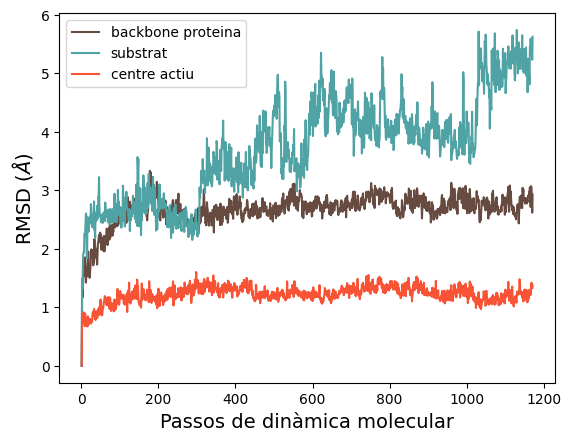

In [3]:
# Ejecutad primero esta celda para obtener el fichero
!wget -nc https://gitlab.uoclabs.uoc.es/prog_bioinf/data/-/raw/master/Unidad3/rmsd_uoc.dat --no-check-certificate

--2025-05-02 10:12:21--  https://gitlab.uoclabs.uoc.es/prog_bioinf/data/-/raw/master/Unidad3/rmsd_uoc.dat
Resolving gitlab.uoclabs.uoc.es (gitlab.uoclabs.uoc.es)... 18.201.253.30
Connecting to gitlab.uoclabs.uoc.es (gitlab.uoclabs.uoc.es)|18.201.253.30|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 69810 (68K) [text/plain]
Saving to: ‘rmsd_uoc.dat’

rmsd_uoc.dat        100%[===================>]  68.17K   362KB/s    in 0.2s    

2025-05-02 10:12:21 (362 KB/s) - ‘rmsd_uoc.dat’ saved [69810/69810]



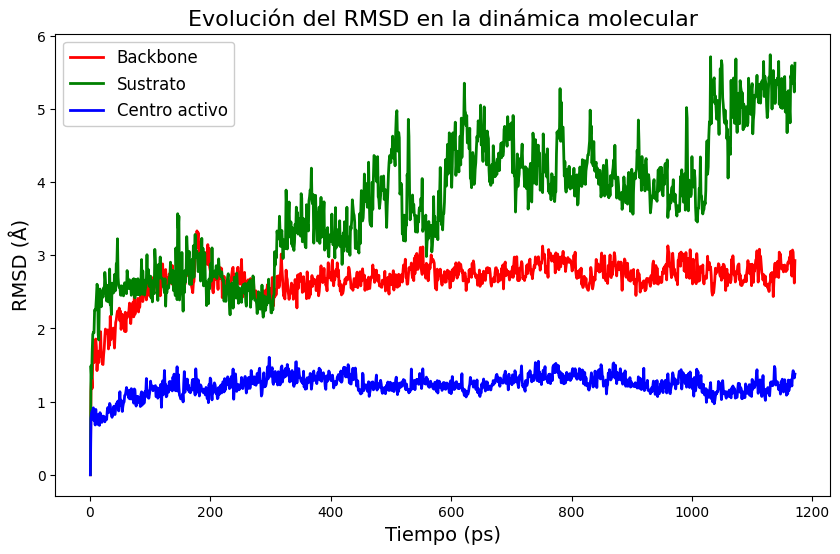

In [5]:
# para poder visualizar el grafico en este notebook
%matplotlib inline

# importamos los módulos necesarios
import matplotlib
import numpy as np
import matplotlib.pyplot as plt

#RESPUESTA
# Cargar datos desde el archivo (asumiendo que está en el mismo directorio)
data = np.loadtxt('rmsd_uoc.dat')  # Si el archivo tiene cabeceras, usar skiprows=1

# Extraer columnas
tiempo = data[:, 0]       # Primera columna: pasos de tiempo
backbone = data[:, 1]     # Segunda columna: backbone
sustrato = data[:, 2]      # Tercera columna: sustrato
centro_activo = data[:, 3] # Cuarta columna: centro activo

# Crear figura y ejes
plt.figure(figsize=(10, 6))

# Dibujar las tres curvas con colores personalizados
plt.plot(tiempo, backbone,'r', label='Backbone', linewidth=2)      # Rojo
plt.plot(tiempo, sustrato, 'g', label='Sustrato', linewidth=2)       # Verde
plt.plot(tiempo, centro_activo, 'b', label='Centro activo', linewidth=2)  # Azul

# Personalizar el gráfico
plt.title('Evolución del RMSD en la dinámica molecular', fontsize=16)
plt.xlabel('Tiempo (ps)', fontsize=14)
plt.ylabel('RMSD (Å)', fontsize=14)
plt.legend(fontsize=12, framealpha=1)  # Leyenda con fondo semitransparente
# Mostrar el gráfico
plt.show()


### **Ejercicio 2**

Haced un gráfico en que se vea el rmsd del backbone de la proteína y el del centro activo en forma de histograma a lo largo de la trayectoria. El gráfico tiene que cumplir las siguientes condiciones:

* Tenéis que tener dos subplots por cada sistema.
* Los dos subplots tienen que compartir el mismo eje de las y
* Lo primero plot tiene que tener transparencia y tiene que ser de color verde rellenado
* El segundo plot solo tiene que tener la línea del histograma de color rojol

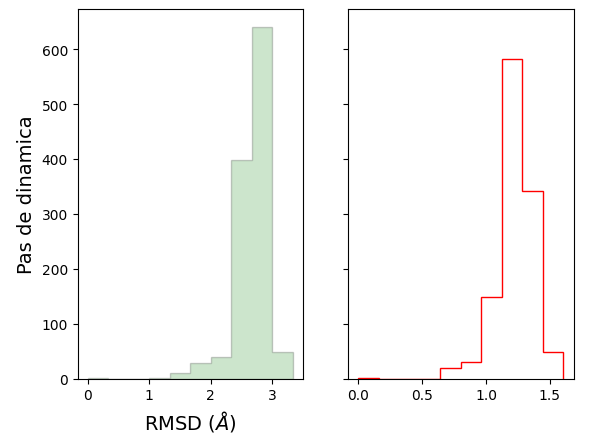


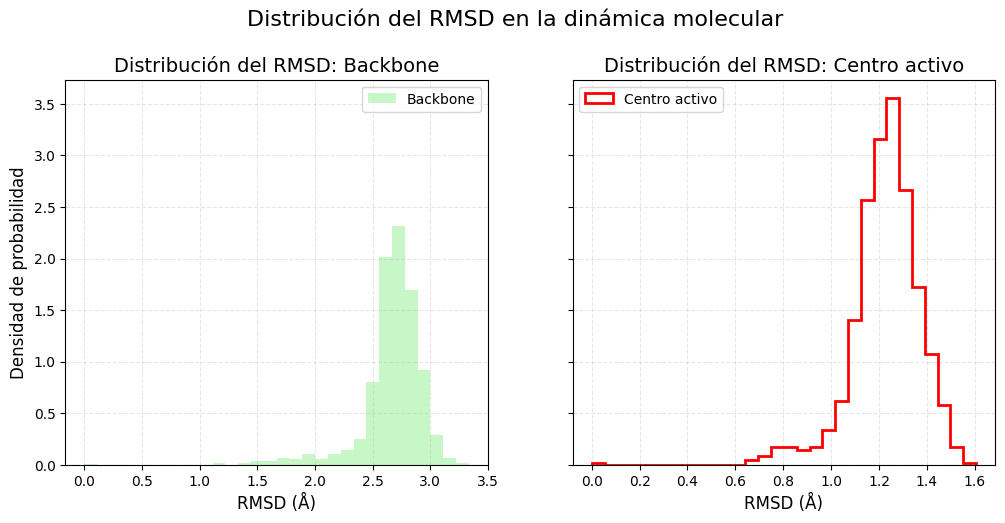

In [28]:
# para poder visualizar el grafico en este notebook
%matplotlib inline

#RESPUESTA
# Cargar datos (ajusta el nombre del archivo si es necesario)
data = np.loadtxt('rmsd_uoc.dat')
# Extraer columnas relevantes
backbone = data[:, 1]       # Columna 2: backbone
centro_activo = data[:, 3]  # Columna 4: centro activo

# Crear figura con 2 subplots que comparten eje Y
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# --- Primer subplot (Backbone, verde relleno) ---
ax1.hist(backbone, bins=30, alpha=0.5, facecolor='lightgreen', linewidth=0.5, density=True, label='Backbone')
ax1.set_title('Distribución del RMSD: Backbone', fontsize=14)
ax1.set_xlabel('RMSD (Å)', fontsize=12)
ax1.set_ylabel('Densidad de probabilidad', fontsize=12)
ax1.grid(linestyle='--', alpha=0.3)
ax1.legend()

# --- Segundo subplot (Centro activo, rojo solo línea) ---
ax2.hist(centro_activo, bins=30, color= 'r', histtype='step', linewidth=2, density=True, label='Centro activo')
ax2.set_title('Distribución del RMSD: Centro activo', fontsize=14)
ax2.set_xlabel('RMSD (Å)', fontsize=12)
ax2.grid(linestyle='--', alpha=0.3)
ax2.legend()

# Ajustes generales
plt.suptitle('Distribución del RMSD en la dinámica molecular', fontsize=16, y=1.02)
plt.show()


### **Ejercicio 3**



Existen una gran variedad de base de datos para todos los tipos de sistemas biológicos en que estemos interesados. Una de ellas es la base de datos llamada **CAZy** (http://www.cazy.org/), en que podemos encontrar descritas todas las familias de módulos catalíticos y de unión de carbohidratos relacionados estructuralmente (o dominios funcionales) de enzimas que degradan, modifican o crean enlaces glicosídicos, denominados **CAZymes**.

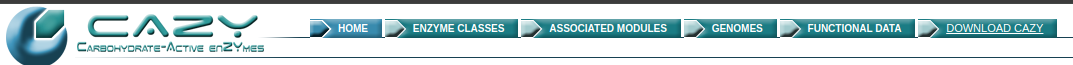

Aparte de consultar directamente la proteína en la que estemos interesados, podemos analizar este conjunto de datos descargándolas desde la página web. En este fichero podemos encontrar varías columnas con información diversa.

* **Primera columna**: Nombre de la clase de CAZyme, seguido con número de la familia a la cual pertenece
* **Segunda columna**: tipo de organismo donde se ha encontrado (Eukariota, bacteria...)
* **Tercera columna**: Organizme exacto donde se ha encontrado
* **Siguientes columnas**: Número de clasificación y en qué bases de datos se pueden encontrar.

Descargaréis un archivo denominado **cazy_fecha_*Aspergillus.txt* en que por motivos de medida, se ha dejado solo la información por los organismos Aspergillus.

In [29]:
# Ejecutad primero esta celda pàra descargar el fichero
!wget -nc https://gitlab.uoclabs.uoc.es/prog_bioinf/data/-/raw/master/Unidad3/cazy_data_Aspergillus.txt --no-check-certificate

--2025-05-02 10:29:45--  https://gitlab.uoclabs.uoc.es/prog_bioinf/data/-/raw/master/Unidad3/cazy_data_Aspergillus.txt
Resolving gitlab.uoclabs.uoc.es (gitlab.uoclabs.uoc.es)... 18.201.253.30
Connecting to gitlab.uoclabs.uoc.es (gitlab.uoclabs.uoc.es)|18.201.253.30|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2879244 (2.7M) [text/plain]
Saving to: ‘cazy_data_Aspergillus.txt’

cazy_data_Aspergill 100%[===================>]   2.75M  4.00MB/s    in 0.7s    

2025-05-02 10:29:46 (4.00 MB/s) - ‘cazy_data_Aspergillus.txt’ saved [2879244/2879244]



En este ejercicio tendremos que crear dos funciones en que las suyas características tienen que ser las siguientes:
* **es_digit()**: Creáis una función en que la variable de entrada se puede corresponder a un texto en que hay letras y números y tiene que devolver solo las letras en una sola variable en formato de string.
* **clasifica_classes_CAZymes()**: Creáis una función en que la variable de entrada sea un fichero de texto descargado de la base de datos CAZy y que clasifique en un diccionario, las clases de CAZymes que hay en aquel fichero y sus valores se corresponden a la cantidad existente por cada clase.

Finalmente, feudo un gráfico de diagrama de sectores (o pie chart en ángulos) en que se vean los porcentajes para cada clase, tal y como se ve en la siguiente figura.


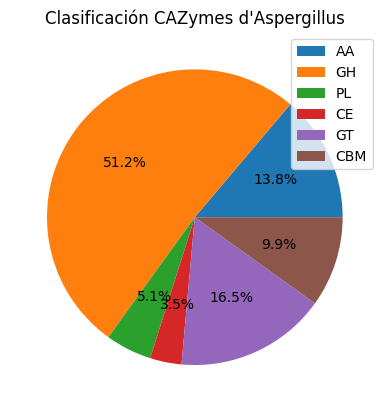

In [36]:
# para poder visualizar el gráàfico en este notebook
%matplotlib inline

# importamos los módulos necessarios
import matplotlib
import numpy as np
import matplotlib.pyplot as plt
data = np.loadtxt('cazy_data_Aspergillus.txt')
def es_digit(data):
  # Función que encuentra si un valor de un string es un digito o no, y solamente develve
  # los valores correspondientes a las letras
  #RESPUESTA
  return ''.join([c for c in texto if not c.isdigit()])


def clasifica_classes_CAZymes(data):
  # Función en que creamos un diccionario en que las keys sueño el tipo de clases
  # que pueden llegar a existir por los CAZymes y los valores se corresponde a la
  # cantidad existente de estas clases.
  CAZymes = {}
  with open(data, "r") as infile:
    for line in infile:
      #respuesta
      # Extraer la primera columna (clase CAZyme)
            primera_columna = linea.strip().split('\t')[0]  # Asumiendo separador por tabulaciones
            # Obtener solo las letras (ej: "GH123" -> "GH")
            clase = es_digit(primera_columna)
            # Actualizar el diccionario
            if clase:
                CAZymes[clase] = CAZymes.get(clase, 0) + 1
    return CAZymes
# Procesar el archivo

resultados = clasifica_classes_CAZymes("cazy_fecha_Aspergillus.txt")

# Calcular porcentajes
total = sum(resultados.values())
porcentajes = {k: (v/total)*100 for k, v in resultados.items()}

# Ordenar por porcentaje descendente
clases_ordenadas = sorted(porcentajes.keys(), key=lambda x: -porcentajes[x])
porcentajes_ordenados = [porcentajes[clase] for clase in clases_ordenadas]

# Crear el gráfico de sectores
plt.figure(figsize=(10, 8))
plt.pie(porcentajes_ordenados,
        labels=clases_ordenadas,
        autopct=lambda p: f'{p:.1f}%',
        startangle=140,
        colors=plt.cm.Pastel1.colors,
        wedgeprops={'linewidth': 1, 'edgecolor': 'white'},
        textprops={'fontsize': 12})

# Añadir título
plt.title('Distribución de clases CAZymes en Aspergillus',
          fontsize=16, pad=20, fontweight='bold')

# Añadir leyenda
plt.legend(title='Clases CAZymes',
           loc='center left',
           bbox_to_anchor=(1, 0.5),
           frameon=False)

# Mostrar el gráfico
plt.tight_layout()
plt.show()



ValueError: could not convert string 'AA5_2' to float64 at row 0, column 1.

###**Ejercicios entregables**

**IMPORTANTE:** Recordad que es necesaria la línea

```python
%matplotlib inline
```
al principio de cada celdilla de código para que podáis visualizar los gráficos en este notebook.

### Ejercicio 1 **<font color="green" size="+2">MU</font>**

Representa en un único gráfico las funciones arcocoseno y arcoseno en el intervalo `[-pi, pi*2]` (en radianes) con un step de `0.05`. Deberíais obtener una imagen de ese estilo:


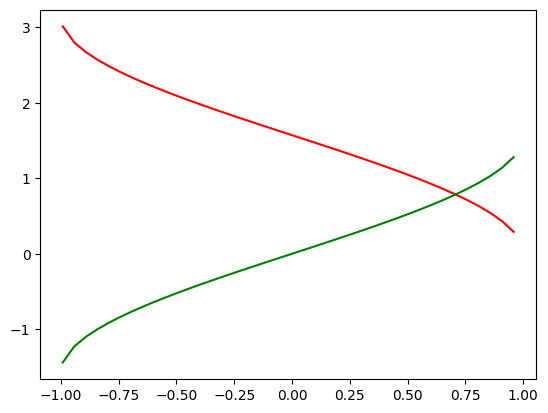

<ipython-input-1-b06f8bec8aa7>:11: RuntimeWarning: invalid value encountered in arccos
  y_arccos = np.arccos(x)
<ipython-input-1-b06f8bec8aa7>:12: RuntimeWarning: invalid value encountered in arcsin
  y_arcsin = np.arcsin(x)


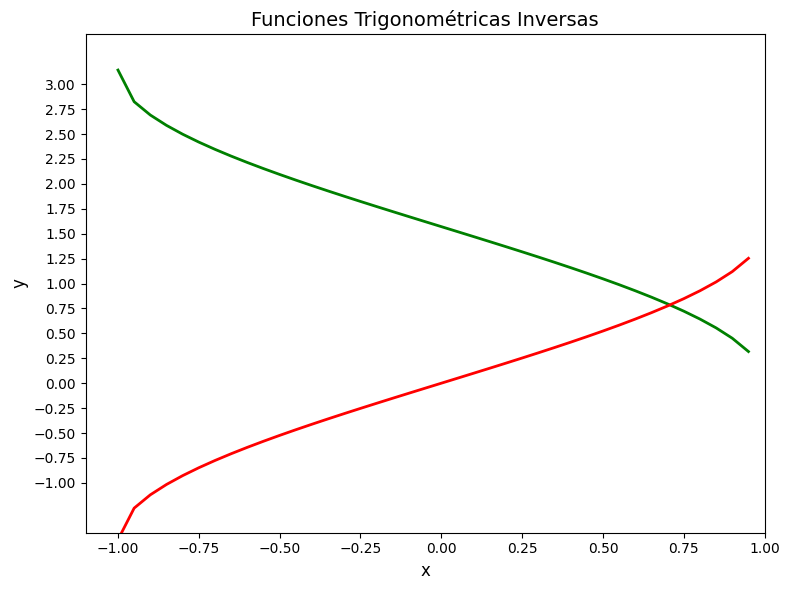

In [1]:
%matplotlib inline

#Respuesta
import numpy as np
import matplotlib.pyplot as plt

# Configuración del intervalo para el eje x (de -1 a 1)
x = np.arange(-1.0, 1.05, 0.05)  # De -1 a 1 con paso de 0.05

# Cálculo de las funciones trigonométricas inversas
y_arccos = np.arccos(x)
y_arcsin = np.arcsin(x)

# Creación del gráfico
plt.figure(figsize=(8, 6))
plt.plot(x, y_arccos, 'g', label='arccos(x)', linewidth=2)
plt.plot(x, y_arcsin, 'r', label='arcsin(x)', linewidth=2)

# Configuración de ejes (de -1 a 1 como en la imagen)
plt.xlim(-1.1, 1)
plt.ylim(-1.5, 3.5)
plt.xticks(np.arange(-1.0, 1.25, 0.25))
plt.yticks(np.arange(-1.0, 3.25, 0.25))

# Etiquetas y título
plt.xlabel('x', fontsize=12)
plt.ylabel('y', fontsize=12)
plt.title('Funciones Trigonométricas Inversas', fontsize=14)
# Mostrar gráfico
plt.tight_layout()
plt.show()

### Ejercicio 2 **<font color="blue" size="+2">EG</font>**

Representa en un gráfico 3D la función `f(x,y) = cos(x) + sin(y)^2` en el intervalo `[-3, 3]` con un step de `0.1`

Podéis consultar ejemplos de graficos 3D aquí: https://matplotlib.org/stable/plot_types/index.html


La representación debería ser similar a la siguiente:

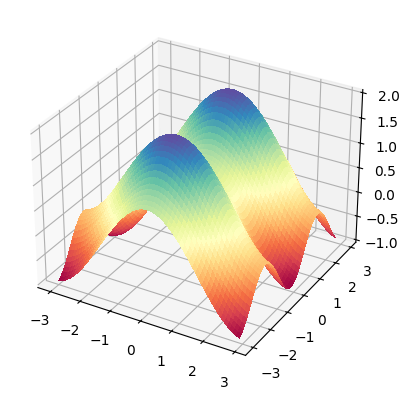

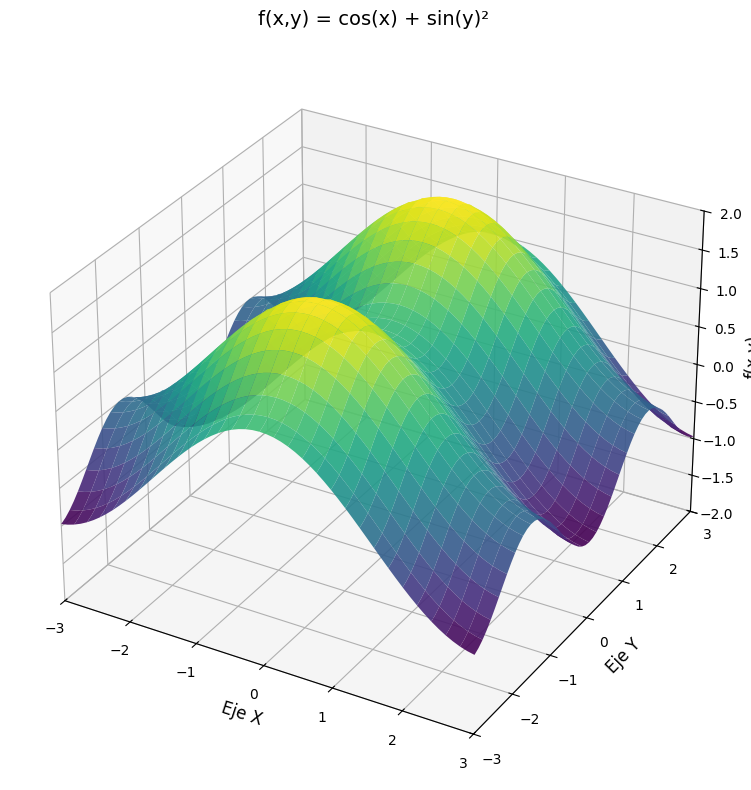

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Configuración del rango y paso
x = np.arange(-3, 3.1, 0.1)
y = np.arange(-3, 3.1, 0.1)
X, Y = np.meshgrid(x, y)

# Cálculo de la función
Z = np.cos(X) + np.sin(Y)**2

# Creación de la figura 3D
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Graficación de la superficie
surf = ax.plot_surface(X, Y, Z, cmap='viridis', edgecolor='none', alpha=0.9)

# Configuración de ejes
ax.set_xlabel('Eje X', fontsize=12)
ax.set_ylabel('Eje Y', fontsize=12)
ax.set_zlabel('f(x,y)', fontsize=12)
ax.set_title('f(x,y) = cos(x) + sin(y)²', fontsize=14, pad=20)

# Ajuste de límites
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.set_zlim(-2, 2)

plt.tight_layout()
plt.show()

### Ejercicio 3 **<font color="blue" size="+2">EG</font>**
Representa la función que quieras de la forma que consideres. Sé creativo a la hora de escoger la función a representar y el intervalo de valores.

Podéis consultar https://matplotlib.org/stable/plot_types/index.html para inspiraros.

<ipython-input-4-55c8f269b9d2>:41: UserWarning: Glyph 129419 (\N{BUTTERFLY}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
<ipython-input-4-55c8f269b9d2>:41: UserWarning: Glyph 128640 (\N{ROCKET}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129419 (\N{BUTTERFLY}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128640 (\N{ROCKET}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


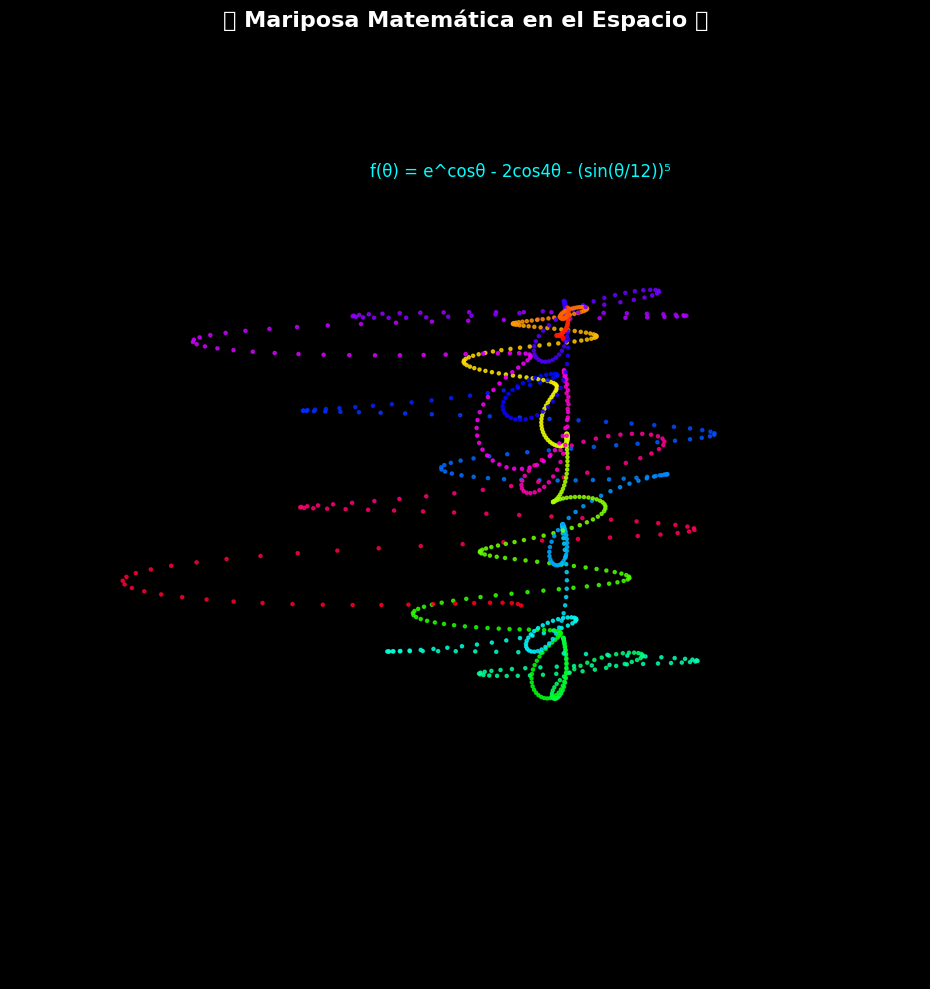

In [4]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Configuración creativa del espacio
theta = np.linspace(0, 12*np.pi, 1000)
r = np.linspace(0.1, 1, 1000)

# Ecuaciones paramétricas para una mariposa
x = r * (np.exp(np.cos(theta)) - 2*np.cos(4*theta) - np.sin(theta/12)**5)
y = r * np.sin(theta) * (np.exp(np.cos(theta)) - 2*np.cos(4*theta) - np.sin(theta/12)**5)
z = np.sin(r*10) * 2  # Efecto de ondulación

# Creación de la figura 3D con fondo estrellado
plt.style.use('dark_background')
fig = plt.figure(figsize=(14, 10))
ax = fig.add_subplot(111, projection='3d')

# Graficación con degradado de colores
ax.scatter(x, y, z, c=theta, cmap='hsv', s=5, alpha=0.8)

# Efectos especiales
ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False
ax.grid(False)

# Configuración artística
ax.set_title('🦋 Mariposa Matemática en el Espacio 🚀',
             fontsize=16, fontweight='bold', pad=30)
ax.set_axis_off()  # Ocultar ejes para efecto más artístico

# Ángulo de vista dinámico
ax.view_init(elev=15, azim=45)

# Añadir texto flotante
ax.text(0, -3, 3, "f(θ) = e^cosθ - 2cos4θ - (sin(θ/12))⁵",
        color='cyan', fontsize=12)

plt.tight_layout()
plt.show()


### Ejercicio 4 **<font color="green" size="+2">MU</font>**

Dados los siguientes datos de meteorología registrados en el aeropuerto de Barcelona, representa en uno o varios gráficos los valores de temperatura máxima, mínima, media anual, huedadrelativa y media de lluvias mensual.

Las posiciones del vector `meteo` son las siguientes:

* Nombre mes
* Temperatura máxima media (°C)
* Temperatura mínima media (°C)
* Temperatura media anual del mes (°C)
* Humedad media relativa (%)
* Media de lluvias mensual (mm)

Hagan las siguientes representaciones gráficas::

1. En un gráfico de lineas, representar las temperaturas màximas, medias y minimas de cada mes (en varios colores)
2. La relación entre la temperatura media y la humidad relativa, en un gráfico de puntos.
3. Un gráfico de barras y línias combinado que exprese la media mensual de lluvia y la humidad relativa, por mes.

No olviden etiquetar ejes (incluyendo unidades y nombre de las variables) y añadir leyendas si se precia.

La representación debe devolver gráficos similares a los siguientes

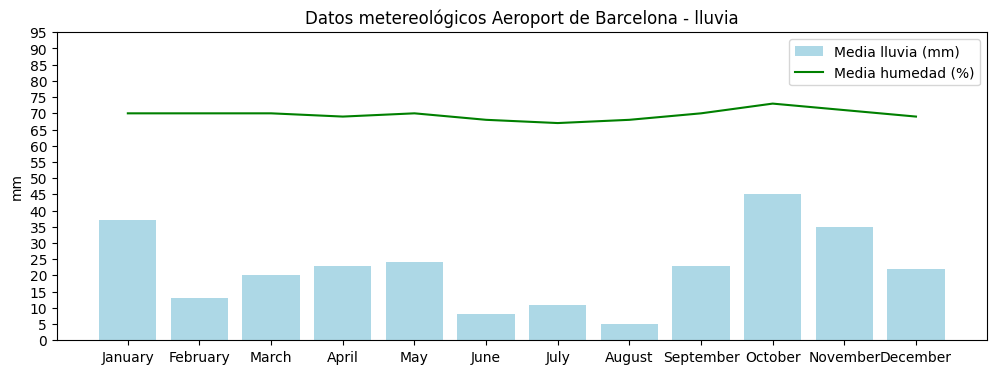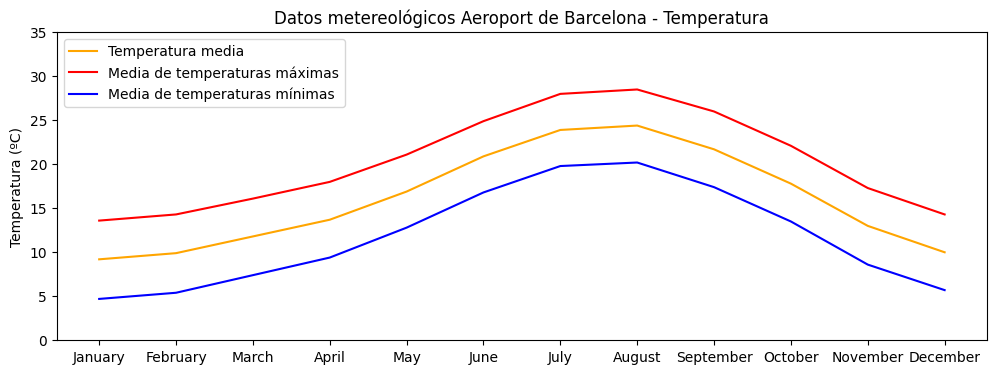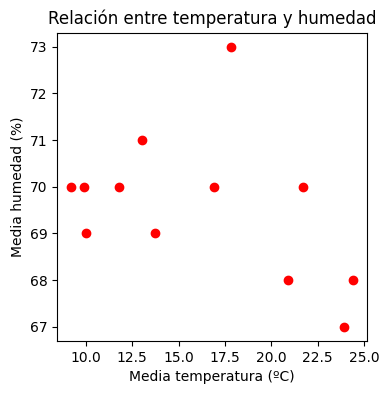

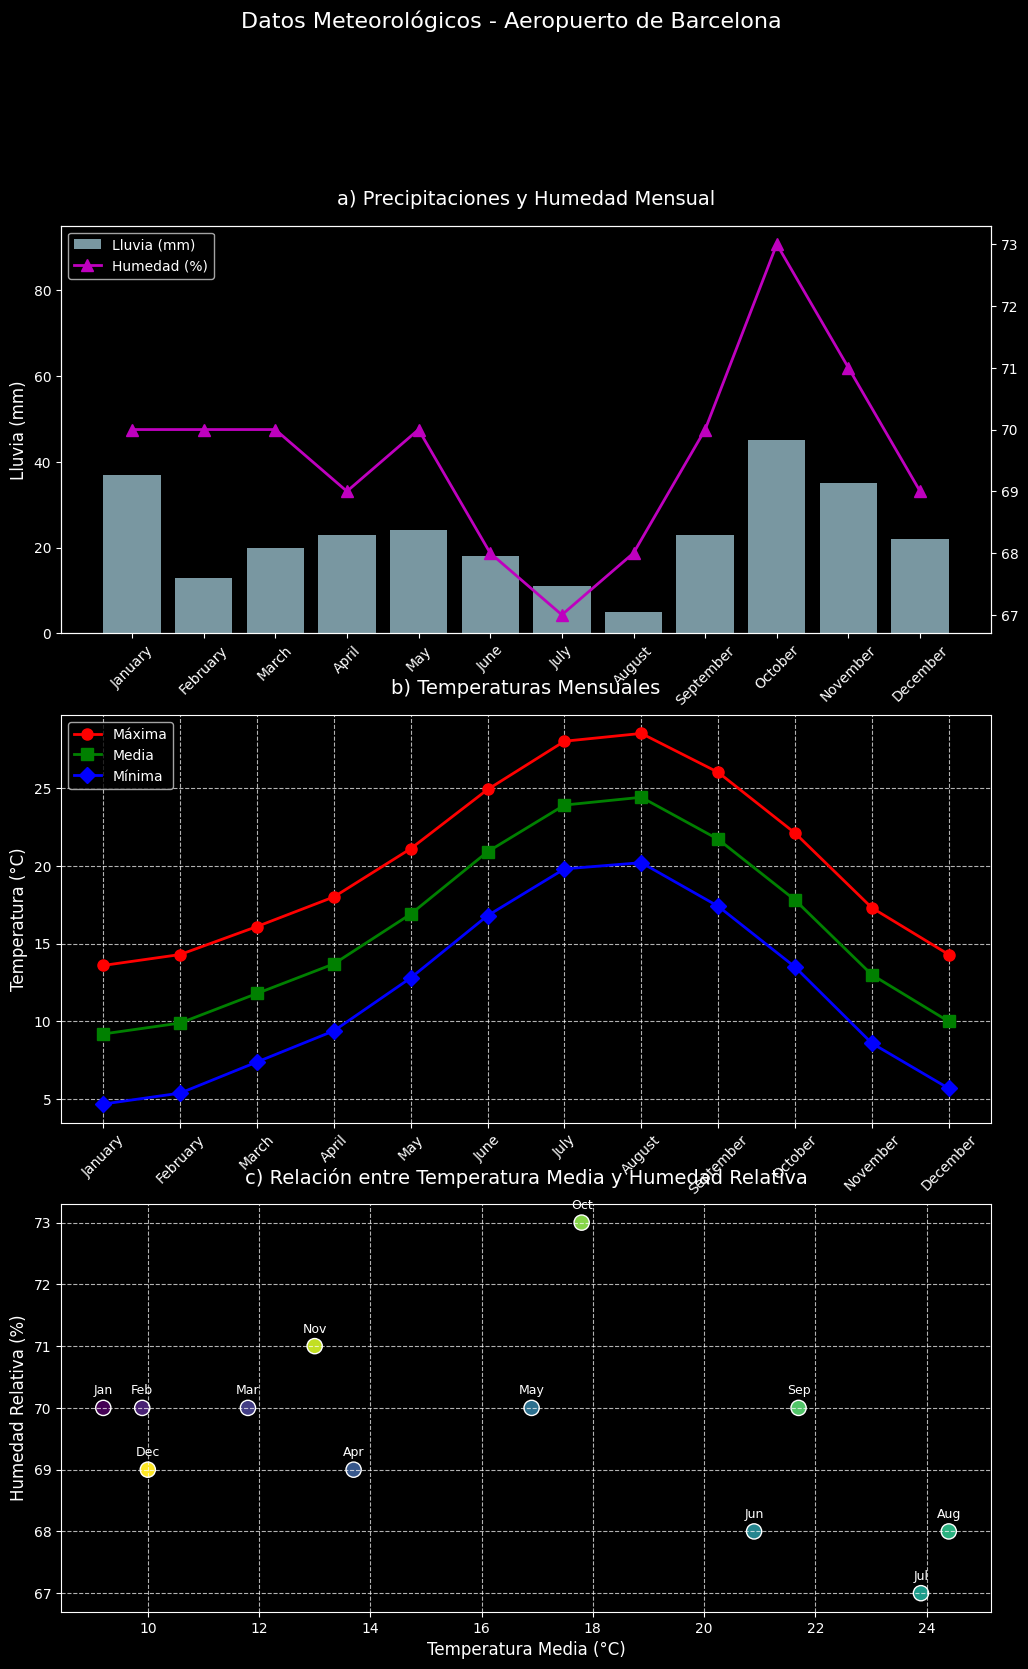

In [23]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np


meteo = [["January", 13.6, 4.7, 9.2, 70, 37],
["February",14.3, 5.4, 9.9, 70, 13],
["March", 16.1, 7.4, 11.8, 70, 20],
["April", 18.0, 9.4, 13.7, 69, 23],
["May", 21.1, 12.8, 16.9, 70, 24],
["June", 24.9, 16.8, 20.9, 68, 18],
["July", 28.0, 19.8, 23.9, 67, 11],
["August", 28.5, 20.2, 24.4, 68, 5],
["September", 26.0, 17.4, 21.7, 70, 23],
["October", 22.1, 13.5, 17.8, 73, 45],
["November", 17.3, 8.6, 13.0, 71, 35],
["December", 14.3, 5.7, 10.0, 69, 22]]

# Respuesta
# Extraer datos
meses = [m[0] for m in meteo]
temp_max = [m[1] for m in meteo]
temp_min = [m[2] for m in meteo]
temp_media = [m[3] for m in meteo]
humedad = [m[4] for m in meteo]
lluvia = [m[5] for m in meteo]

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 18))
plt.suptitle('Datos Meteorológicos - Aeropuerto de Barcelona', y=1, fontsize=16)
## GRÁFICO 1: Lluvia y Humedad
ax1b = ax1.twinx()
bars = ax1.bar(meses, lluvia, color='lightblue', alpha=0.7, label='Lluvia (mm)')
line = ax1b.plot(meses, humedad, 'm-^', markersize=8, linewidth=2, label='Humedad (%)')
ax1.set_title('a) Precipitaciones y Humedad Mensual', pad=15, fontsize=14)
ax1.set_ylabel('Lluvia (mm)', fontsize=12)
ax1.set_ylim(0, 95)
ax1.tick_params(axis='x', rotation=45)

## GRÁFICO 2: Temperaturas mensuales
ax2.plot(meses, temp_max, 'r-o', label='Máxima', linewidth=2, markersize=8)
ax2.plot(meses, temp_media, 'g-s', label='Media', linewidth=2, markersize=8)
ax2.plot(meses, temp_min, 'b-D', label='Mínima', linewidth=2, markersize=8)
ax2.set_title('b) Temperaturas Mensuales', pad=15, fontsize=14)
ax2.set_ylabel('Temperatura (°C)', fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.7)
ax2.legend(loc='upper left', fontsize=10)
ax2.tick_params(axis='x', rotation=45)

## GRÁFICO 3: Relación Temperatura-Humedad
colors = plt.cm.viridis(np.linspace(0, 1, len(meses)))
scatter = ax3.scatter(temp_media, humedad, c=colors, s=120, edgecolor='w', linewidth=1)
ax3.set_title('c) Relación entre Temperatura Media y Humedad Relativa', pad=15, fontsize=14)
ax3.set_xlabel('Temperatura Media (°C)', fontsize=12)
ax3.set_ylabel('Humedad Relativa (%)', fontsize=12)
ax3.grid(True, linestyle='--', alpha=0.7)

# Añadir etiquetas de meses cerca de los puntos
for i, mes in enumerate(meses):
    ax3.annotate(mes[:3], (temp_media[i], humedad[i]),
                textcoords="offset points", xytext=(0,10),
                ha='center', fontsize=9)

# Leyenda unificada
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax1b.get_legend_handles_labels()
ax1.legend(lines + lines2, labels + labels2, loc='upper left', fontsize=10)
plt.show()